# Comparaison des deux labels en plan glissant (réentraînement chaque mois)

**Question.** Entre le label « 180 jours pour tous » (A) et le label relatif `H_i = clip(3 × écart p90, 45, 90 jours)` (B), lequel capte le plus de CA réellement perdu quand on rejoue la production : un réentraînement chaque mois, une évaluation à chaque date ?

**Protocole.** À chaque date de test `T_test`, chaque chaîne est entraînée sur toutes les photos mensuelles dont le label est connu à `T_test` :

- **A** : photos avec `T ≤ T_test − 180 jours` (label « aucun achat pendant 180 jours »).
- **B** : photos avec `T ≤ T_test − 90 jours` (label relatif, horizon ≤ 90 jours). À chaque date, B dispose donc de plus de photos.

Les deux sont **évaluées contre la même vérité** (aucun achat pendant 180 jours après `T_test`), classées par `p × V`. Dates de test : du 22/09/2023 au 22/03/2024 (7 dates, les seules où la vérité est observable). Le label B est suivi en plus sur 3 dates (22/04, 22/05 et 22/06/2024), où la vérité à 180 jours n'existe plus : on y mesure B sur son propre label, à titre de stabilité seulement (ce CA « perdu » est surestimé, voir `06_label_horizon_calibration.ipynb`).

**Mesures.** AUC contre la vérité, CA des vrais partants capté dans la liste de K clients (K = 700 et 2 000), marge à rétention 10 / 20 / 30 % (`r × 24,65 % × CA capté`). Chaque modèle est la moyenne de 3 graines (réduit le bruit d'entraînement). Intervalle de la différence B − A : bootstrap sur les clients (200 tirages, mêmes tirages pour A et B), moyenné sur les 7 dates.

Réguliers : ≥ 6 jours d'achat sur 180 jours, écart médian ≤ 30 jours. 12 variables sur 180 jours. Dates d'origine du dataset. Périmètre du dataset, non extrapolé.

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"        # reproductibilité
from pathlib import Path
import time
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

pd.set_option("display.max_columns", 50, "display.width", 220, "display.float_format", lambda x: f"{x:,.3f}")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PARQUET = ROOT / "data" / "sales.parquet"
con = duckdb.connect()
con.execute("SET memory_limit='4GB'")
con.execute(f"SET temp_directory='{ROOT / 'data' / '.duckdb_tmp'}'")


def q(sql):
    return con.execute(sql).fetchdf()


C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a")
INK, INK2, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({"axes.facecolor": SURF, "figure.facecolor": SURF, "axes.edgecolor": "#c3c2b7", "axes.grid": True,
                     "grid.color": GRID, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

HIST, MIN_PURCH, MED_GAP_MAX, ANN, TRUTH_DAYS = 180, 6, 30, 2, 180
KREL, HMIN, HMAX = 3.0, 45, 90                       # label relatif B
K_LIST, RETENTIONS, MARGIN = (700, 2000), (0.10, 0.20, 0.30), 0.2465
N_BOOT, N_SEEDS, SEED = 200, 3, 0
FIRST = pd.Timestamp("2023-03-22")
ALL = [FIRST + pd.DateOffset(months=j) for j in range(16)]          # 22/03/2023 -> 22/06/2024

In [2]:
t0 = time.time()
con.execute(f"CREATE OR REPLACE VIEW sales AS SELECT * FROM read_parquet('{PARQUET}')")
con.execute("""
CREATE OR REPLACE TABLE bn AS
SELECT client_id, date_order AS d, sum(sales_net) AS rev
FROM sales WHERE date_order BETWEEN DATE '2022-09-22' AND DATE '2024-09-22'
GROUP BY 1, 2 HAVING sum(sales_net) > 0.01""")
DATA_END = pd.Timestamp(q("SELECT max(d) AS m FROM bn").iloc[0, 0])
TRUTH_DATES = [T for T in ALL if T + pd.Timedelta(days=TRUTH_DAYS) <= DATA_END]      # vérité à 180 j observable
TEST_DATES = [T for T in TRUTH_DATES if T >= pd.Timestamp("2023-09-22")]
EXT_DATES = [T for T in ALL if T not in TRUTH_DATES]
print(f"fin des données {DATA_END:%d/%m/%Y} · dates de test {TEST_DATES[0]:%d/%m/%Y} -> {TEST_DATES[-1]:%d/%m/%Y} ({len(TEST_DATES)}) · "
      f"dates sans vérité (B seul) : {', '.join(f'{T:%d/%m/%Y}' for T in EXT_DATES)} · {time.time() - t0:.0f}s")

fin des données 22/09/2024 · dates de test 22/09/2023 -> 22/03/2024 (7) · dates sans vérité (B seul) : 22/04/2024, 22/05/2024, 22/06/2024 · 2s


In [3]:
FEATS = ["recency_days", "freq_180d", "freq_90d", "freq_prev_90d", "rev_180d", "rev_90d", "rev_prev_90d",
         "gap_median", "gap_p90", "recency_ratio", "freq_trend", "rev_trend"]


def photo(T):
    t = f"{T:%Y-%m-%d}"
    df = q(f"""
    WITH hist AS (SELECT client_id, d, rev, d - lag(d) OVER (PARTITION BY client_id ORDER BY d) AS gap
                  FROM bn WHERE d < DATE '{t}' AND d >= DATE '{t}' - {HIST}),
    agg AS (SELECT client_id, count(*) AS freq_180d, median(gap) AS gap_median, quantile_cont(gap, 0.9) AS gap_p90,
                   max(d) AS last_d, sum(rev) AS rev_180d,
                   count(*) FILTER (WHERE d >= DATE '{t}' - 90) AS freq_90d,
                   count(*) FILTER (WHERE d <  DATE '{t}' - 90) AS freq_prev_90d,
                   coalesce(sum(rev) FILTER (WHERE d >= DATE '{t}' - 90), 0) AS rev_90d,
                   coalesce(sum(rev) FILTER (WHERE d <  DATE '{t}' - 90), 0) AS rev_prev_90d
            FROM hist GROUP BY 1),
    fut AS (SELECT client_id, min(d) - DATE '{t}' AS next_gap FROM bn
            WHERE d >= DATE '{t}' AND d < DATE '{t}' + {TRUTH_DAYS} GROUP BY 1)
    SELECT a.*, date_diff('day', a.last_d, DATE '{t}') AS recency_days, f.next_gap
    FROM agg a LEFT JOIN fut f USING (client_id)""")
    df["next_gap"] = df.next_gap.astype(float)
    df = df[(df.freq_180d >= MIN_PURCH) & (df.gap_median <= MED_GAP_MAX)].sort_values("client_id").copy()
    df["V"] = ANN * df.rev_180d
    df["recency_ratio"] = df.recency_days / df.gap_p90.clip(lower=1)
    df["freq_trend"] = df.freq_90d / (df.freq_prev_90d + 1)
    df["rev_trend"] = df.rev_90d / (df.rev_prev_90d + 1)
    ng = df.next_gap.fillna(9999)
    df["H"] = (KREL * df.gap_p90).clip(HMIN, HMAX)
    df["label_B"] = (ng >= df.H).astype(int)                        # perdu au sens du label relatif (horizon <= 90 j)
    df["gone"] = (ng >= TRUTH_DAYS).astype(int)                     # vérité : aucun achat pendant 180 j (valide si T est dans TRUTH_DATES)
    df["T"] = T
    return df.reset_index(drop=True)


t0 = time.time()
PH = {T: photo(T) for T in ALL}
print(f"{len(PH)} photos en {time.time() - t0:.0f}s")
pd.DataFrame({"Photo": [f"{T:%d/%m/%Y}" for T in ALL], "Clients": [len(d) for d in PH.values()],
              "Perdus label B (%)": [100 * d.label_B.mean() for d in PH.values()],
              "Vraiment partis (%)": [100 * d.gone.mean() if T in TRUTH_DATES else np.nan for T, d in PH.items()]}).set_index("Photo")

16 photos en 2s


,Clients,Perdus label B (%),Vraiment partis (%)
Photo,,,
22/03/2023,62239,9.573,3.822
22/04/2023,61394,9.045,3.880
22/05/2023,59003,6.918,3.476
22/06/2023,59074,6.663,3.438
22/07/2023,59641,6.705,3.568
22/08/2023,60331,7.081,3.703
22/09/2023,60312,7.460,3.996
22/10/2023,60624,7.415,3.954
22/11/2023,62590,8.610,4.699


## Plan glissant : entraînement et évaluation à chaque date

In [4]:
def fit_predict(train_dates, label_col, test_df):
    tr = pd.concat([PH[T] for T in train_dates], ignore_index=True)
    y = tr[label_col].to_numpy()
    p = np.zeros(len(test_df))
    for sd in range(N_SEEDS):
        m = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.08, early_stopping=False, random_state=SEED + sd)
        m.fit(tr[FEATS], y)
        p += m.predict_proba(test_df[FEATS])[:, 1] / N_SEEDS
    return p


def capture(score, loss, K, idx=None):
    if idx is not None:
        score, loss = score[idx], loss[idx]
    top = np.argpartition(-score, K - 1)[:K]
    return loss[top].sum() / loss.sum()


CHAINS = {"A": ("gone", 180), "B": ("label_B", 90)}
SC = {}                                     # (chaîne, T_test) -> probabilités
NPH = {}
t0 = time.time()
for Tt in TEST_DATES + EXT_DATES:
    test = PH[Tt]
    for ch, (col, hmax) in CHAINS.items():
        if ch == "A" and Tt in EXT_DATES:
            continue
        train_dates = [T for T in ALL if (Tt - T).days >= hmax]
        SC[(ch, Tt)] = fit_predict(train_dates, col, test)
        NPH[(ch, Tt)] = len(train_dates)
    print(f"{Tt:%d/%m/%Y} A:{NPH.get(('A', Tt), '-')} photos · B:{NPH[('B', Tt)]} photos · {time.time() - t0:.0f}s")

22/09/2023 A:1 photos · B:4 photos · 10s


22/10/2023 A:2 photos · B:5 photos · 22s


22/11/2023 A:3 photos · B:6 photos · 37s


22/12/2023 A:4 photos · B:7 photos · 55s


22/01/2024 A:5 photos · B:8 photos · 75s


22/02/2024 A:6 photos · B:9 photos · 99s


22/03/2024 A:7 photos · B:10 photos · 125s


22/04/2024 A:- photos · B:11 photos · 142s


22/05/2024 A:- photos · B:12 photos · 162s


22/06/2024 A:- photos · B:13 photos · 567s


## Résultats sur les 7 dates avec vérité à 180 jours

In [5]:
rng = np.random.default_rng(SEED)
rows, BOOT = [], {K: {"A": [], "B": []} for K in K_LIST}
IDX = {Tt: [rng.integers(0, len(PH[Tt]), len(PH[Tt])) for _ in range(N_BOOT)] for Tt in TEST_DATES}
for Tt in TEST_DATES:
    d = PH[Tt]
    V, Y = d.V.to_numpy(), d.gone.to_numpy()
    loss = V * Y
    row = {"Date de test": f"{Tt:%d/%m/%Y}", "Vraiment parti (M€)": loss.sum() / 1e6,
           "Photos A": NPH[("A", Tt)], "Photos B": NPH[("B", Tt)]}
    for ch in ("A", "B"):
        row[f"AUC {ch}"] = roc_auc_score(Y, SC[(ch, Tt)])
    for K in K_LIST:
        cap = {ch: capture(SC[(ch, Tt)] * V, loss, K) for ch in ("A", "B")}
        for ch in ("A", "B"):
            row[f"K={K} {ch} (%)"] = 100 * cap[ch]
            BOOT[K][ch].append(np.array([capture(SC[(ch, Tt)] * V, loss, K, ix) for ix in IDX[Tt]]))
        row[f"K={K} B−A (pts)"] = 100 * (cap["B"] - cap["A"])
    rows.append(row)
per_date = pd.DataFrame(rows).set_index("Date de test")
per_date

,Vraiment parti (M€),Photos A,Photos B,AUC A,AUC B,K=700 A (%),K=700 B (%),K=700 B−A (pts),K=2000 A (%),K=2000 B (%),K=2000 B−A (pts)
Date de test,,,,,,,,,,,
22/09/2023,65.302,1,4,0.848,0.851,31.346,33.199,1.853,46.882,49.866,2.985
22/10/2023,68.833,2,5,0.885,0.881,52.503,52.238,-0.265,66.369,65.843,-0.525
22/11/2023,86.552,3,6,0.877,0.880,45.931,48.044,2.113,58.975,60.850,1.875
22/12/2023,83.901,4,7,0.891,0.893,48.964,50.626,1.662,65.867,66.175,0.308
22/01/2024,70.757,5,8,0.896,0.896,48.314,49.801,1.487,65.641,66.324,0.683
22/02/2024,58.315,6,9,0.896,0.895,48.402,49.435,1.033,64.294,64.474,0.180
22/03/2024,60.728,7,10,0.893,0.892,50.430,51.175,0.746,65.219,65.524,0.306


In [6]:
rows = []
for K in K_LIST:
    A = np.mean(BOOT[K]["A"], axis=0)                 # moyenne sur les dates, par tirage
    B = np.mean(BOOT[K]["B"], axis=0)
    d = B - A
    pa, pb = per_date[f"K={K} A (%)"].mean(), per_date[f"K={K} B (%)"].mean()
    # CA capté en M€ et marge (moyenne sur les dates)
    capt_a = np.mean([capture(SC[("A", Tt)] * PH[Tt].V.to_numpy(), PH[Tt].V.to_numpy() * PH[Tt].gone.to_numpy(), K) * (PH[Tt].V * PH[Tt].gone).sum() for Tt in TEST_DATES]) / 1e6
    capt_b = np.mean([capture(SC[("B", Tt)] * PH[Tt].V.to_numpy(), PH[Tt].V.to_numpy() * PH[Tt].gone.to_numpy(), K) * (PH[Tt].V * PH[Tt].gone).sum() for Tt in TEST_DATES]) / 1e6
    row = {"K": K, "CA capté A (%)": pa, "CA capté B (%)": pb, "B − A (pts)": pb - pa,
           "IC 95 % de B − A (pts)": f"[{100 * np.percentile(d, 2.5):+.1f} ; {100 * np.percentile(d, 97.5):+.1f}]",
           "Dates où B > A": f"{int((per_date[f'K={K} B−A (pts)'] > 0).sum())} sur {len(TEST_DATES)}",
           "CA capté A (M€/date)": capt_a, "CA capté B (M€/date)": capt_b}
    for r in RETENTIONS:
        row[f"Marge r={r:.0%} A (M€/an)"] = r * MARGIN * capt_a
        row[f"Marge r={r:.0%} B (M€/an)"] = r * MARGIN * capt_b
    rows.append(row)
summary = pd.DataFrame(rows).set_index("K").T
print("AUC moyen A : %.3f · B : %.3f" % (per_date["AUC A"].mean(), per_date["AUC B"].mean()))
summary

AUC moyen A : 0.884 · B : 0.884


K,700,2000
CA capté A (%),46.556,61.892
CA capté B (%),47.788,62.722
B − A (pts),1.233,0.830
IC 95 % de B − A (pts),[+0.3 ; +2.0],[+0.1 ; +1.5]
Dates où B > A,6 sur 7,6 sur 7
CA capté A (M€/date),32.926,43.736
CA capté B (M€/date),33.834,44.342
Marge r=10% A (M€/an),0.812,1.078
Marge r=10% B (M€/an),0.834,1.093
Marge r=20% A (M€/an),1.623,2.156


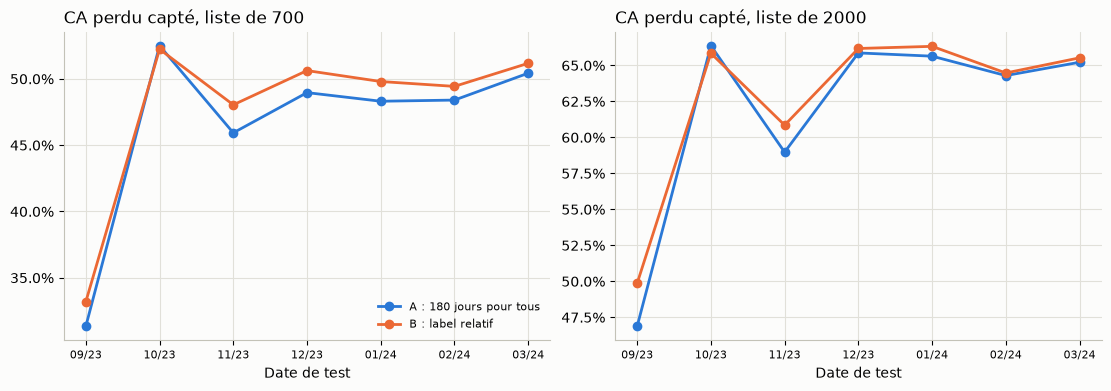

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True, sharey=False)
x = np.arange(len(TEST_DATES))
for ax, K in zip(axes, K_LIST):
    ax.plot(x, per_date[f"K={K} A (%)"], "o-", color=C["blue"], lw=2, label="A : 180 jours pour tous")
    ax.plot(x, per_date[f"K={K} B (%)"], "o-", color=C["orange"], lw=2, label="B : label relatif")
    ax.set_xticks(x)
    ax.set_xticklabels([f"{T:%m/%y}" for T in TEST_DATES], fontsize=8)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter())
    ax.set_title(f"CA perdu capté, liste de {K}", loc="left")
    ax.set_xlabel("Date de test")
axes[0].legend(frameon=False, loc="lower right", fontsize=8)
plt.show()

## Label B sur 10 dates : stabilité, jusqu'au 22/06/2024

Sur les 3 dernières dates, la vérité à 180 jours n'est plus observable : on mesure B sur **son propre label** (« perdu » au sens de `H_i`). Le CA capté y est calculé sur le CA déclaré perdu, surestimé d'environ 1,7 fois par rapport au CA vraiment parti : seule la stabilité dans le temps compte, pas le niveau.

In [8]:
rows = []
for Tt in TEST_DATES + EXT_DATES:
    d = PH[Tt]
    V, L = d.V.to_numpy(), d.label_B.to_numpy()
    loss = V * L
    row = {"Date": f"{Tt:%d/%m/%Y}", "Photos d'entraînement": NPH[("B", Tt)], "Perdus (% des clients)": 100 * L.mean(),
           "AUC sur le label B": roc_auc_score(L, SC[("B", Tt)])}
    for K in K_LIST:
        row[f"K={K} CA capté, label B (%)"] = 100 * capture(SC[("B", Tt)] * V, loss, K)
    row["Contre la vérité 180 j ?"] = "oui" if Tt in TRUTH_DATES else "non (pas assez de recul)"
    rows.append(row)
pd.DataFrame(rows).set_index("Date")

,Photos d'entraînement,Perdus (% des clients),AUC sur le label B,"K=700 CA capté, label B (%)","K=2000 CA capté, label B (%)",Contre la vérité 180 j ?
Date,,,,,,
22/09/2023,4,7.460,0.841,27.257,42.051,oui
22/10/2023,5,7.415,0.863,40.727,54.133,oui
22/11/2023,6,8.610,0.862,38.072,51.127,oui
22/12/2023,7,9.258,0.862,37.408,51.374,oui
22/01/2024,8,8.507,0.865,37.446,52.013,oui
22/02/2024,9,8.482,0.866,35.233,48.733,oui
22/03/2024,10,8.832,0.851,34.456,48.380,oui
22/04/2024,11,8.179,0.841,33.337,46.801,non (pas assez de recul)
22/05/2024,12,6.228,0.849,34.106,47.573,non (pas assez de recul)
